# Setup

In [1]:
lapply(c('viridis', 'ggthemes', 'skimr'),
       function(pkg_name) { if(! pkg_name %in% installed.packages()) { install.packages(pkg_name)} } )

library(viridis)    # A nice color scheme for plots.
library(ggthemes)   # Common themes to change the look and feel of plots.
library(scales)     # Graphical scales map data to aesthetics in plots.
library(skimr)      # Better summaries of data.
library(lubridate)  # Date library from the tidyverse.
library(tidyverse)  # Data wrangling packages.
library(bigrquery)  # Data extraction from Google BigQuery
library(data.table )

# Load required libraries
library(dplyr)
library(tidyr)
library(purrr)
library(broom)
library(patchwork)

install.packages("pROC")
library(pROC)


## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}


[[1]]
NULL

[[2]]
NULL

[[3]]
NULL

Loading required package: viridisLite


Attaching package: ‘scales’


The following object is masked from ‘package:viridis’:

    viridis_pal



Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr   1.2.1     ✔ readr   2.2.0
✔ forcats 1.0.1     ✔ stringr 1.6.0
✔ ggplot2 4.0.2     ✔ tibble  3.3.1
✔ purrr   1.2.1     ✔ tidyr   1.3.2
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ readr::col_factor() masks scales::col_factor()
✖ purrr::discard()    masks scales::discard()
✖ dplyr::filter()     masks stats::filter()
✖ dplyr::lag()        masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘data.table’


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is

## Load and merge data

In [2]:
current_directory <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48"
output_dir <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data"

#Load demographic data
demo_file = paste0(current_directory, "/data/Demographic_and_ancestry_covariates.csv")
demo  <- read_csv(demo_file) |> 
    select(-c(income, education)) |> 
    rename(age = age_at_last_event)

#Load SES data
ses_file = paste0(current_directory, "/data/SES_data.csv")
ses_data  <- read_csv(ses_file)

#MERGE
demo_sdoh<-merge(demo, ses_data, on="person_id", how="inner")

#Load PRS data
PRS_file = paste0(current_directory, "/data/adjusted_PRS_scores.csv")
PRS  <- read_csv(PRS_file) 

#Load Case control info 
name_of_file_in_bucket <- 'Case_Control_df.csv'
system(paste0("gsutil cp gs://rw-migration-aou-rw-55feedb6/notebooks/Case_Control_df.csv ."), intern=T)
case_control  <- read_csv(name_of_file_in_bucket)

merged_data<-merge(PRS, case_control, on="person_id", how="left")
merged_data<-merge(merged_data, demo_sdoh, on="person_id", how="left")

Rows: 135557 Columns: 51
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (9): SexGender, ancestry_pred, education, where_born, military, health...
dbl  (30): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (8): AIAN, Asian, Black, Mid, Multiple, PI, White, His
dttm  (1): basics_survey_datetime
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 214915 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (13): person_id, income, education, per_poverty_threshold, individual_po...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 135557 Columns: 9
── Column specification ────────────────────

character(0)

Rows: 265954 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
merged_data <- merged_data %>%
  mutate(
    SexGenderCis_male = ifelse(SexGender == "Cis_male", 1, 0),
    SexGenderCis_female = ifelse(SexGender == "Cis_female", 1, 0),
    SexGenderSGM = ifelse(SexGender == "SGM", 1, 0)
  )

merged_data$age2<-merged_data$age^2

## Set up lists

In [4]:
diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "ProstateC", "t2d", "t1d")

disease_name_mapping <- c(
    "Asthma" = "Asthma", 
    "Afib" = "Afib",
    "CKD" = "CKD", 
    "CHD" = "CHD",
  "t2d" = "T2D",
  "t1d" = "T1D",
    "BreastC" = "Breast Cancer",
    "ProstateC" = "Prostate Cancer"
)

domains <-c('individual_poverty', 'education',
         'fraction_assisted_income', 'fraction_no_high_school_education', 'lower_median_income', 
         'fraction_no_health_insurance', 'fraction_poverty', 'fraction_vacant_housing', 'deprivation_index'
)

domains_order <- domains

# Regressions

## Models

In [5]:
# Model labels
models <- c("Base", "Genetic", "Social", "Joint", "Interaction")

# Function to generate formulas for disease-domain pairs
generate_formulas <- function(disease, domain) {
  # Base covariates
  covariates <- c("age", "age2", "record_depth", "visit_frequency")
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease == "CKD" || disease == "t1d") {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease %in% c("BreastC", "ProstateC")) { sex_terms <- character(0) }

  # Combine covariates
  base <- paste(c(covariates, sex_terms), collapse = " + ")
  genetic_score <- paste0(disease, "_adjusted_score")
  social_score <- domain
  interaction <- paste0(genetic_score, ":", social_score)

  # Return all 5 models
  list(
    as.formula(paste(disease, "~", base)),
    as.formula(paste(disease, "~", paste(c(base, genetic_score), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, social_score), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, genetic_score, social_score), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, genetic_score, social_score, interaction), collapse = " + ")))
  )
}

## Auc

In [6]:
fit_and_extract <- function(formulas, disease, domain, models, data) {
  map2(formulas, models, ~ {
    # Disease-specific filtering
    filtered_data <- data
    if (disease %in% c("CKD", "t1d")) {
      filtered_data <- filtered_data %>% filter(SexGenderSGM == 0)
    }
    if (disease == "BreastC") {
      filtered_data <- filtered_data %>% filter(SexGenderCis_female == 1)
    }
    if (disease == "ProstateC") {
      filtered_data <- filtered_data %>% filter(SexGenderCis_male == 1)
    }
      

    # Handle missing vars
    vars_in_model <- all.vars(.x)
    filtered_data <- filtered_data %>% 
      filter(if_all(all_of(vars_in_model), ~ !is.na(.)))

    # Fit model
    model <- glm(.x, data = filtered_data, family = binomial(link = "logit"))

    # Predictions
    preds <- predict(model, type = "response")
    actuals <- model$y
    ids <- filtered_data$person_id

    # AUC + CI
    if (length(unique(actuals)) > 1) {
      roc_obj <- roc(actuals, preds, quiet = TRUE)
      auc <- as.numeric(roc_obj$auc)
      auc_ci <- ci.auc(roc_obj)
    } else {
      auc <- NA
      auc_ci <- c(NA, NA, NA)
    }

    list(
      coefficients = tidy(model) %>%
        mutate(Disease = disease,
               Domain = domain, 
               Model = .y,
               AUC = auc,
               AUC_CI_Lower = auc_ci[1],
               AUC_CI_Upper = auc_ci[3]),
      predictions = tibble(
        person_id = ids,
        actual = actuals,
        prediction = preds,
        Disease = disease,
        Domain = domain, 
        Model = .y
      )
    )
  })
}

# combos
combinations <- expand_grid(
  disease = unlist(diseases),
  domain  = domains
)

results <- combinations %>%
  rowwise() %>%
  mutate(model_results = list(
    fit_and_extract(generate_formulas(disease, domain), disease, domain, models, merged_data)
  )) %>%
  ungroup()


# All coefficients
coeff_results <- results %>%
  mutate(coeffs = map(model_results, ~ bind_rows(map(.x, "coefficients")))) %>%
  select(disease, coeffs) %>%
  unnest(coeffs)

# All predictions
pred_results <- results %>%
  mutate(preds = map(model_results, ~ bind_rows(map(.x, "predictions")))) %>%
  select(disease, preds) %>%
  unnest(preds) 



Warning message:
“There were 45 warnings in `mutate()`.
The first warning was:
ℹ In argument: `model_results = list(...)`.
ℹ In row 1.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 44 remaining warnings.”


# Prepare Plot 

In [7]:
# Step 2: Join domain lookup and restrict all models to the mapped domain
auc_plot_data <- coeff_results %>%
  filter(Model %in% c("Base", "Genetic", "Social", "Joint", "Interaction")) %>%
  filter(!is.na(AUC)) %>%
  select(Disease, Domain, Model, AUC, AUC_CI_Lower, AUC_CI_Upper) %>%
  distinct()


model_colors <- c(
  "Base"    = "#E69F00", # orange
  "Genetic" = "#0072B2", # blue
  "Social"  = "#009E73", # bluish green
  "Joint"   = "#D55E00", # vermillion
  "Interaction" = "grey"
)

domain_name_mapping <- c(
    "individual_poverty" = "Individual Poverty",
    "education" = "Lower Individual Education", 
    "fraction_assisted_income" = "Assisted Income (%)",
  "fraction_no_high_school_education" = "High School Education (%)",
  "lower_median_income" = "Median Income",
    "fraction_no_health_insurance" = "Health Insurance (%)",
    "fraction_poverty" = "Poverty (%)",
    'fraction_vacant_housing' = "Vacant Housing (%)",
    'deprivation_index' = "Deprivation Index"
)




# Map names
auc_plot_data <- auc_plot_data  %>% mutate(Disease = as.character(Disease), 
                                                    Disease = recode(Disease, 
                                                    !!!disease_name_mapping, 
                                                                     .default = Disease) )

auc_plot_data <- auc_plot_data  %>% mutate(Domain = as.character(Domain), 
                                                    Domain = recode(Domain, 
                                                    !!!domain_name_mapping, 
                                                                     .default = Domain) )

facet_order <- c(
  "Breast Cancer", "Prostate Cancer", "Afib", "T2D",
  "CKD", "CHD", "Asthma", "T1D"
)

auc_plot_data <- auc_plot_data %>%
  mutate(
    Model = factor(Model, c("Base", "Social", "Genetic",
                                    "Joint", "Interaction")),
    Disease = factor(Disease, facet_order)
  )

auc_plot_data$Domain <- factor(
  auc_plot_data$Domain,
  levels = c("Individual Education", "Individual Poverty", "Assisted Income (%)", "High School Education (%)",
            "Median Income", "Health Insurance (%)", "Poverty (%)", "Vacant Housing (%)", "Deprivation Index")
)



In [8]:
# Create the plot
auc_plot <- ggplot(auc_plot_data, aes(x = Domain, y = AUC, color = Model)) +
  geom_point(
    position = position_dodge(width = 0.7),
    size = 3.5
  ) +
  geom_errorbar(
    aes(ymin = AUC_CI_Lower, ymax = AUC_CI_Upper),
    position = position_dodge(width = 0.7),
    width = 0.4
  ) +
  facet_wrap(
    ~ Disease,
    scales = "free"
  ) +
  labs(
    title = " ",
    x = " ",
    y = "AUC"
  ) +
  scale_color_manual(values = model_colors) +
  theme_minimal(base_size = 25) +
  theme(
    legend.position = "bottom",
    axis.text.x = element_text(angle = 90, hjust = 1),
    strip.text = element_text(size = 30, face = "bold"),
    legend.title = element_text(face = "bold", hjust = .5),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(size = 0.1, color = "black"),
      
  ) +

  geom_vline(
    xintercept = seq(
      1.5,
      length(unique(auc_plot_data$Domain)) - 0.5,
      1
    ),
    color = "darkgrey"
  ) 

write_excel_csv(auc_plot_data, file.path(output_dir, "auc_joint_model_plot_data.csv"))

Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.”


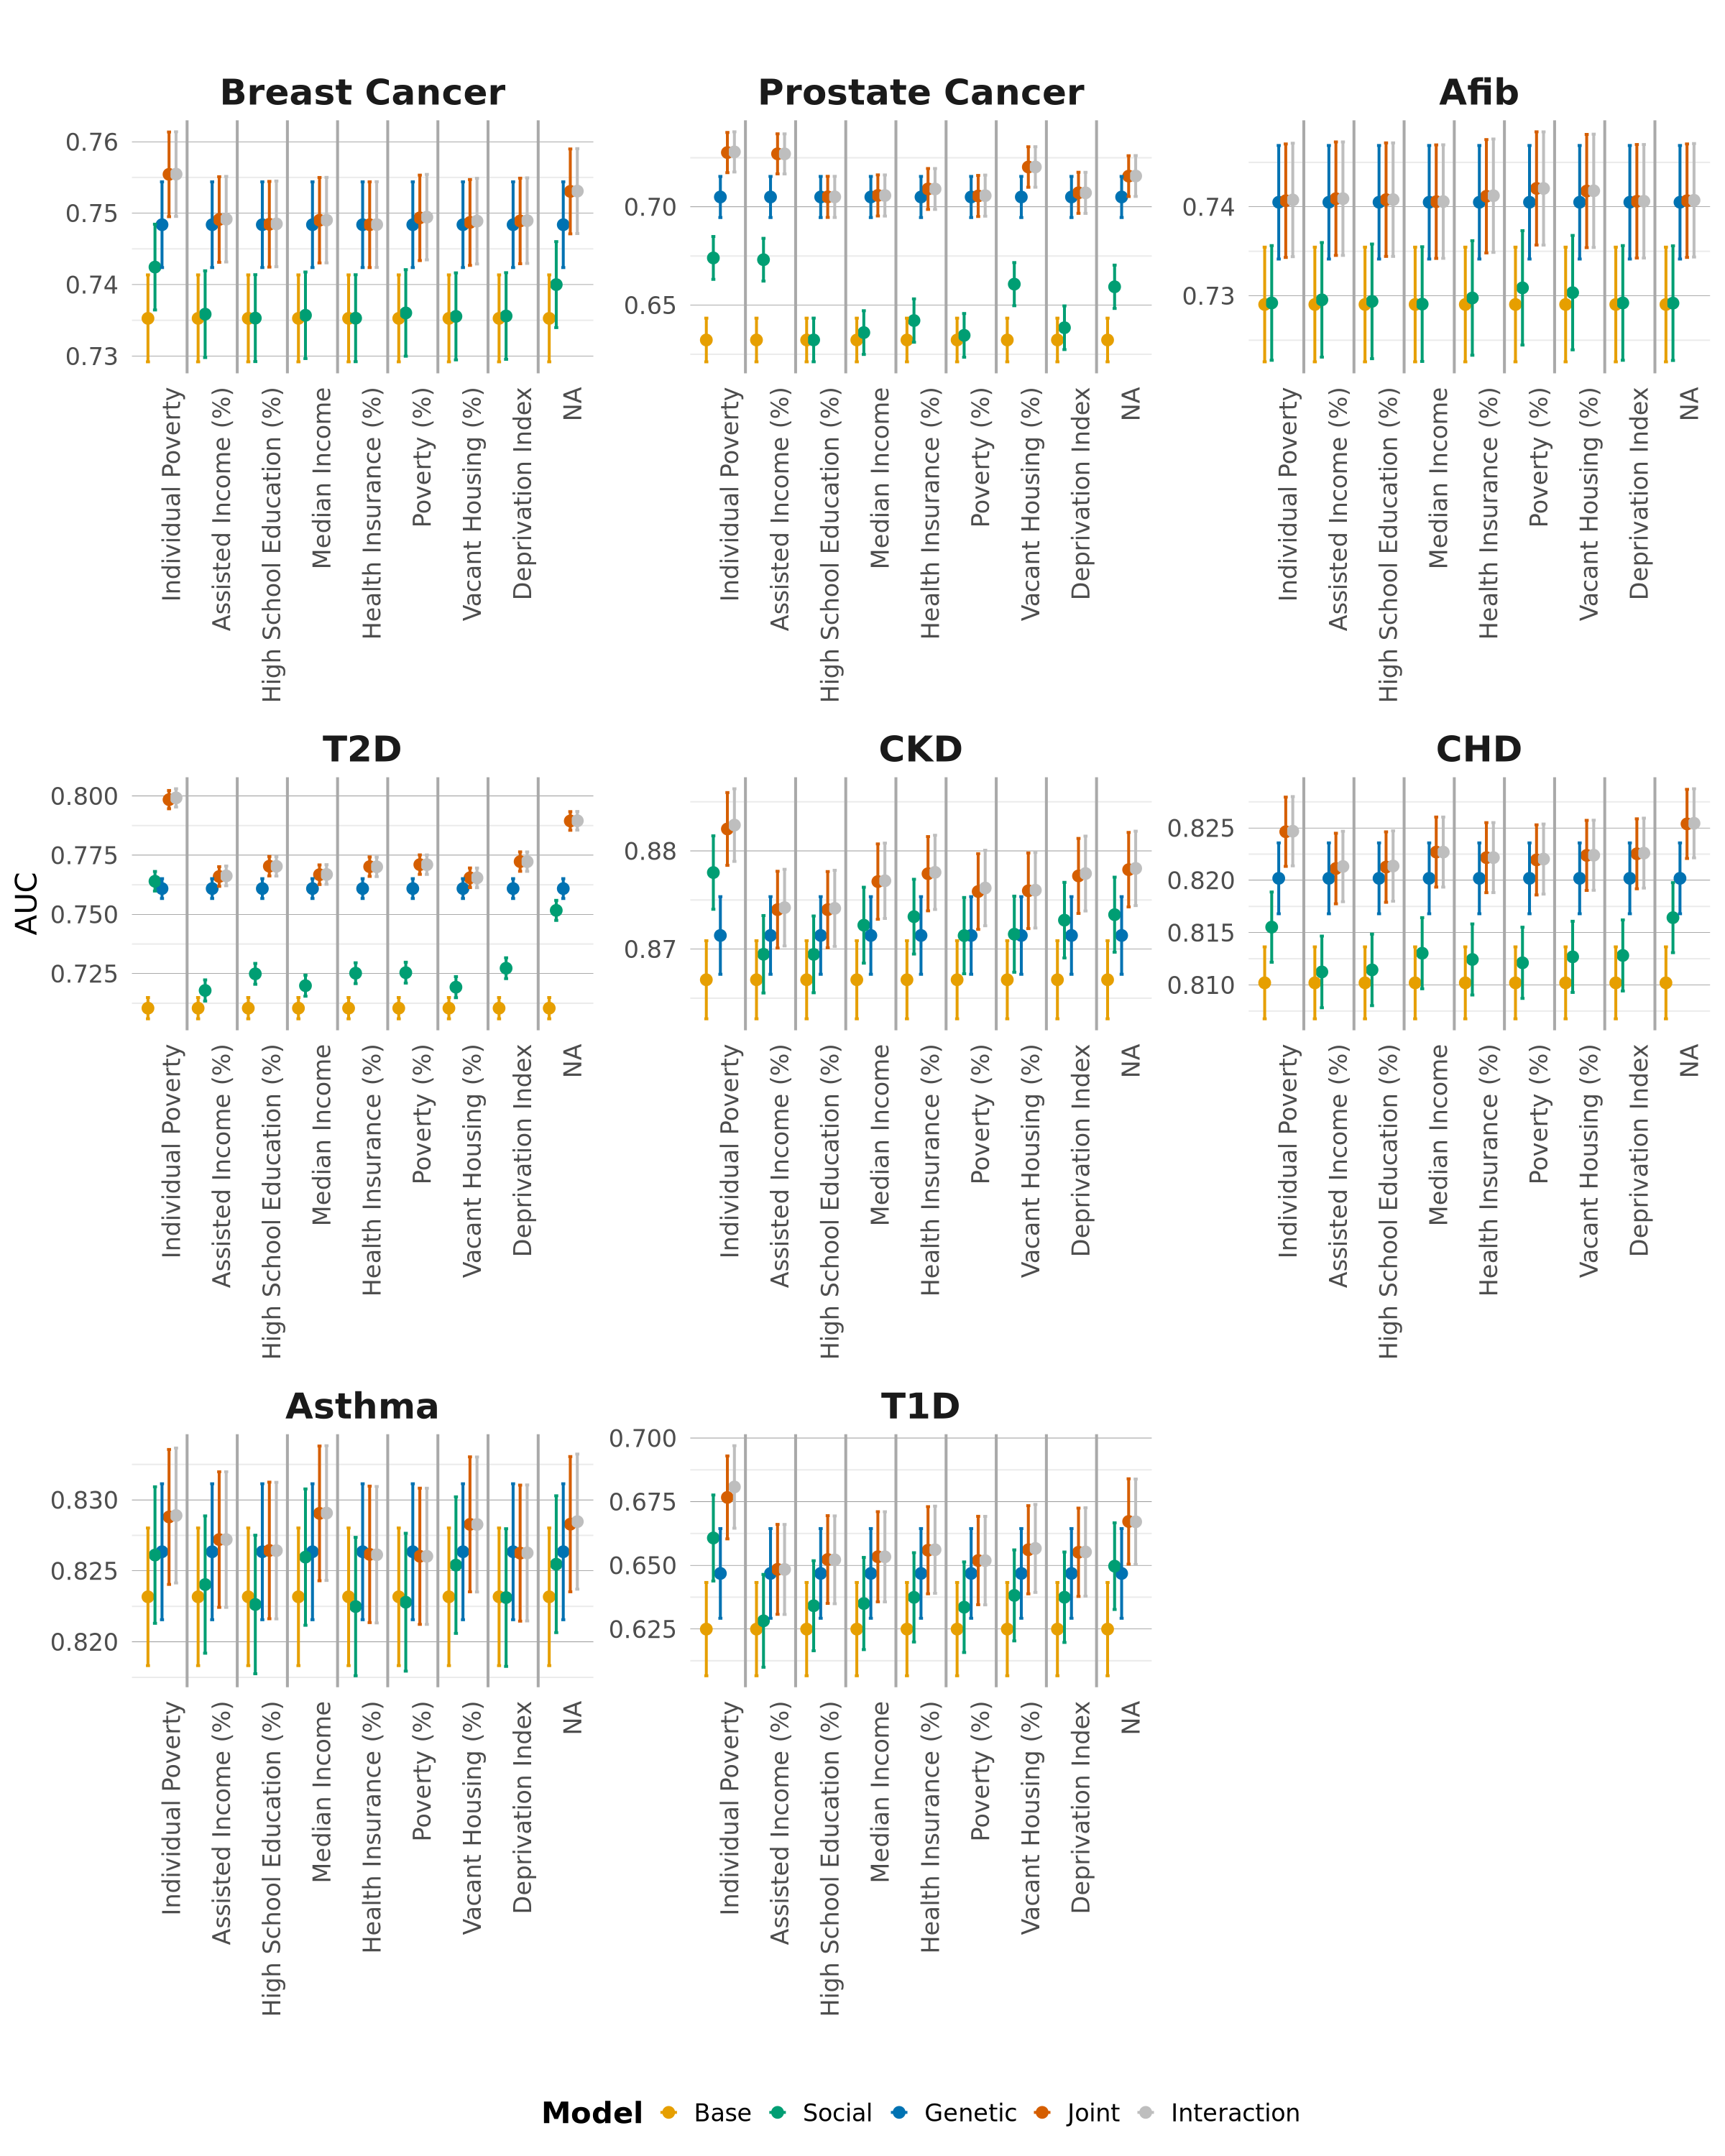

In [9]:
options(repr.plot.width = 20, repr.plot.height = 25)  # Set width and height

auc_plot

# DeLong's Test of Significance 

In [10]:
compare_models_auc <- function(df, disease_name, domain_name) {
  
  models <- unique(df$Model)
  comparisons <- combn(models, 2, simplify = FALSE)
  
  map_dfr(comparisons, function(comp) {
    m1 <- comp[1]
    m2 <- comp[2]
    
    roc1 <- roc(
      df$actual[df$Model == m1],
      df$prediction[df$Model == m1],
      quiet = TRUE
    )
    
    roc2 <- roc(
      df$actual[df$Model == m2],
      df$prediction[df$Model == m2],
      quiet = TRUE
    )
    
    test <- roc.test(roc1, roc2, method = "delong")
    
    ci1 <- ci.auc(roc1, conf.level = 0.95)
    ci2 <- ci.auc(roc2, conf.level = 0.95)
    
    se1 <- as.numeric(ci1[3] - ci1[2]) / 3.92
    se2 <- as.numeric(ci2[3] - ci2[2]) / 3.92
    
    tibble(
      Disease = disease_name,
      Domain = domain_name,
      Model1 = m1,
      Model2 = m2,
      AUC1 = as.numeric(auc(roc1)),
      se1 = se1,
      AUC2 = as.numeric(auc(roc2)),
      se2 = se2,
      p_value = test$p.value
    )
  })
}

auc_comparisons <- pred_results %>%
  group_by(Disease, Domain) %>%
  group_map(~ compare_models_auc(.x, .y$Disease, .y$Domain)) %>%
  bind_rows()

auc_comparisons <- auc_comparisons %>%
  mutate(
    bonf_p = 0.05 / nrow(auc_comparisons),      # Bonferroni threshold
    p_value_bonf = p_value * nrow(auc_comparisons), # adjusted p-value
    p_value_bonf = ifelse(p_value_bonf > 1, 1, p_value_bonf), # cap at 1
    significant = p_value < bonf_p,              # TRUE/FALSE flag
    level = case_when(
      p_value_bonf < 0.05e-10 ~ "***",
      p_value_bonf < 0.05  ~ "**",
      p_value < 0.05  ~ "*",
      TRUE ~ ""
    )
  )

# Map names
auc_comparisons <- auc_comparisons  %>% mutate(Disease = as.character(Disease), 
                                                    Disease = recode(Disease, 
                                                    !!!disease_name_mapping, 
                                                                     .default = Disease) )


write_excel_csv(auc_comparisons, file.path(output_dir, "auc_comparisons_sdoh_joint_modeling_one_by_one.csv"))

nrow(auc_comparisons)


[1] 720

In [11]:
auc_comparisons[auc_comparisons$Model1 == "Joint" & auc_comparisons$Model2 == "Interaction", ] |> 
    arrange(p_value)

Disease,Domain,Model1,Model2,AUC1,se1,AUC2,se2,p_value,bonf_p,p_value_bonf,significant,level
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<chr>
T2D,individual_poverty,Joint,Interaction,0.7984396,0.0009824194,0.7991868,0.0009813065,2.523536e-07,6.944444e-05,0.0001816946,TRUE,**
CKD,fraction_poverty,Joint,Interaction,0.8758618,0.0009833298,0.8762200,0.0009812294,8.520082e-04,6.944444e-05,0.6134459315,FALSE,*
CKD,deprivation_index,Joint,Interaction,0.8774524,0.0009738923,0.8776943,0.0009722059,6.100802e-03,6.944444e-05,1.0000000000,FALSE,*
CKD,individual_poverty,Joint,Interaction,0.8822337,0.0009455368,0.8826300,0.0009435434,7.657066e-03,6.944444e-05,1.0000000000,FALSE,*
CKD,fraction_assisted_income,Joint,Interaction,0.8740140,0.0009977706,0.8742198,0.0009964993,8.873738e-03,6.944444e-05,1.0000000000,FALSE,*
T2D,fraction_vacant_housing,Joint,Interaction,0.7654522,0.0010573438,0.7654293,0.0010573169,1.253025e-02,6.944444e-05,1.0000000000,FALSE,*
T1D,individual_poverty,Joint,Interaction,0.6766748,0.0041548323,0.6807773,0.0041341500,1.600644e-02,6.944444e-05,1.0000000000,FALSE,*
CHD,fraction_assisted_income,Joint,Interaction,0.8211251,0.0008601348,0.8213188,0.0008592459,1.824188e-02,6.944444e-05,1.0000000000,FALSE,*
Prostate Cancer,education,Joint,Interaction,0.7156499,0.0026498555,0.7157167,0.0026496220,2.096718e-02,6.944444e-05,1.0000000000,FALSE,*
